## Executive Summary:

- All of the Test 1 matrices behave as expected. I find both the signed sparsity plots and the sign comparison plots informative and nice to look at. You almost certainly only need a subset of the plots present to demonstrate the main point in your slides.
- Test 2A matrices behave as expected, causing high error in non-O(n^3)+FP implementations except for the O(n^3) + emulation + scaling implementations.
- Test 2B matrices do not behave as expected for the emulation code: they cause high error in ALL non-O(n^3)+FP and they are NOT gamed by Emulation + FP64 Diagonal computation.
    - I believe this is to do with a shortcoming in the source code for the emulation. Even the vanilla OZIMMU code (i.e., without my scaling and FP64 diagonal computations wrapping it) zeroes out entries of enormous magnitude. I am also observing this behavior with the vanilla OZIMMU on Test2A matrices but the scaling fixes it there. The circular shifting which defeats the OZIMMU scaling is causing the largest errors in the off diagonals so adding FP64 diagonal computations does little to help. I have to think more on this.
- Test 2C matrices behave as expected, causing high error in ALL non-O(n^3)+FP

In [1]:
import h5py
import pandas as pd
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import inspect

DOUBLE_MACHINE_EPS = 2**-52
MATPLOTLIB_SHAPES = ['.','o', '^', 's', 'P', 'X', 'D']
MATPLOTLIB_COLOR_IDX = 0
MATPLOTLIB_SHAPE_IDX = 0

def get_matrix(query, metadata_df, matrices_dict, exact_str_match=False):
    temp_df = metadata_df
    for field, value in query.items():
        if isinstance(value, str):
            if exact_str_match:
                temp_df = temp_df[temp_df[field] == value]
            else:
                temp_df = temp_df[temp_df[field].str.contains(value)]
        else:
            temp_df = temp_df[temp_df[field] == value]
    if len(temp_df) > 1:
        print("Found multiple matches!")
        print(temp_df)
        return None
    elif len(temp_df) == 0:
        print("Found no matches!")
        return None
    else:
        return matrices_dict[f'{temp_df["matrix_id"].iloc[0]}'][:]

# for a given matrix type and a given implementation, plot boxplots of the componentwise nomalized error ratio for each dimension
def plot_all_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    all_forward_error_constants = []
    for mat_id, ref_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_ref_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()
        all_forward_error_constants.append(abs((vals - ref_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals)))
    
    # plot
    ax.boxplot(all_forward_error_constants, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}", y=1.05)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot the max of the componentwise nomalized error ratio for each dimension
def plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    global MATPLOTLIB_COLOR_IDX
    global MATPLOTLIB_SHAPE_IDX
    global MATPLOTLIB_SHAPES
    
    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate max componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    max_forward_error_constants = []
    for mat_id, ref_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_ref_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()

        max_forward_error_constants.append(max(abs((vals - ref_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals))))
   
    # plot
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.plot(
        dims,
        max_forward_error_constants,
        c = list(mpl.colors.TABLEAU_COLORS.values())[MATPLOTLIB_COLOR_IDX],
        marker = MATPLOTLIB_SHAPES[MATPLOTLIB_SHAPE_IDX],
        markersize = 16,
        label=f"{impl.split('-')[0]}"
    )
    ax.set_title(f"{impl.split('-')[0]}", y=1.05)
    MATPLOTLIB_COLOR_IDX = (MATPLOTLIB_COLOR_IDX + 1)%len(mpl.colors.TABLEAU_COLORS)
    MATPLOTLIB_SHAPE_IDX = (MATPLOTLIB_SHAPE_IDX + 1)%len(MATPLOTLIB_SHAPES)

# for a given matrix type and a given implementation, plot the max of the componentwise nomalized error ratio for each dimension
def plot_max_componentwise_fn_factors_vs_dim_test3(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    global MATPLOTLIB_COLOR_IDX
    global MATPLOTLIB_SHAPE_IDX
    global MATPLOTLIB_SHAPES
    
    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == "test3") & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == "U(1,2)") & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == "U(1,2)") & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate max componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    max_forward_error_constants = []
    for mat_id, ref_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_ref_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()

        max_forward_error_constants.append(max(abs((vals - ref_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals))))

    print(max_forward_error_constants[0:10])
    
    # plot
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.plot(
        dims,
        max_forward_error_constants,
        c = list(mpl.colors.TABLEAU_COLORS.values())[MATPLOTLIB_COLOR_IDX],
        marker = MATPLOTLIB_SHAPES[MATPLOTLIB_SHAPE_IDX],
        markersize = 16,
        label=f"{impl.split('-')[0]}"
    )
    ax.set_title(f"{impl.split('-')[0]}", y=1.05)
    MATPLOTLIB_COLOR_IDX = (MATPLOTLIB_COLOR_IDX + 1)%len(mpl.colors.TABLEAU_COLORS)
    MATPLOTLIB_SHAPE_IDX = (MATPLOTLIB_SHAPE_IDX + 1)%len(MATPLOTLIB_SHAPES)
    
# for a given matrix type and a given implementation, plot boxplots of the componentwise relative errors for each dimension
def plot_all_componentwise_unsigned_relative_errors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_relative_errors
    # note the potential divide-by-zero issue here
    dims = []
    unsigned_relative_errors = []
    for mat_id, ref_mat_id in zip(filtered_ids, filtered_ref_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        unsigned_relative_errors.append(abs((vals - ref_vals) / ref_vals))
    
    # plot
    ax.boxplot(unsigned_relative_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    #ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot boxplots of the componentwise absolute errors for each dimension
def plot_all_componentwise_unsigned_absolute_errors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_absolute_errors
    dims = []
    unsigned_absolute_errors = []
    for mat_id, ref_mat_id in zip(filtered_ids, filtered_ref_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        unsigned_absolute_errors.append(abs(vals - ref_vals))
    
    # plot
    ax.boxplot(unsigned_absolute_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    #ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

def plot_matrix_sparsity(input_type, impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrix
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")
    
    bounds = [-0.5, 0.5, 1.5]
    
    cmap = mpl.colors.ListedColormap(["none", "red"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A<0, cmap=cmap, norm=norm)

    cmap = mpl.colors.ListedColormap(["none", "green"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A>0, cmap=cmap, norm=norm)
    
    cmap = mpl.colors.ListedColormap(["none", "white"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A==0, cmap=cmap, norm=norm)

    ax.text(x=problem_size/2, y=problem_size+0.05*(problem_size), s=f"# zeros: {(A==0).sum()}", horizontalalignment="center")
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def plot_matrix_sparsity_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrices
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    ref_matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)
    A_ref = matrices_dict[f"{ref_matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")
    
    bounds = [-0.5, 0.5, 1.5]
    
    cmap = mpl.colors.ListedColormap(["white", "black"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(np.sign(A_ref) != np.sign(A), cmap=cmap, norm=norm)

    ax.text(x=problem_size/2, y=problem_size+0.05*(problem_size), s=f"# zeros: {(A==0).sum()}", horizontalalignment="center")
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def plot_heatmap_comparisons_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrices
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    ref_matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)
    A_ref = matrices_dict[f"{ref_matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")

    data = np.abs(A_ref - A)/np.abs(A_ref)
    
    im = ax.imshow(data)
    ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def plot_matrix_absolute_error_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrices
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    ref_matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)
    A_ref = matrices_dict[f"{ref_matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")

    data = np.abs(A_ref - A)
    
    im = ax.imshow(data)
    ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

    
# for a given matrix type and a given implementation, plot boxplots of the componentwise nomalized error ratio for each dimension
def plot_matrix_componentwise_fn_factors(data, impl, vmin, vmax, ax, logscale):
    cmap = mpl.cm.get_cmap('viridis')
    if logscale:
        normalizer = mpl.colors.Normalize(np.log10(vmin), np.log10(vmax))
        im = ax.imshow(np.log10(data), cmap=cmap, norm=normalizer)
    else:
        normalizer = mpl.colors.Normalize(vmin, vmax)
        im = ax.imshow(data, cmap=cmap, norm=normalizer)
    #ax.figure.colorbar(im, ax=ax, shrink=0.5)
    ax.set_title(f"{impl.split('-')[0]}")
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def relative_error_heatmaps(
    impls,
    ref_impl,
    input_type,
    problem_size,
    n_rows,
    n_cols,
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
):
    print(f"Input Type          : {input_type}")
    print(f"Problem Size        : {problem_size}")
    print(f"Logscale?           : {logscale}")
    print(f"Shared Colorbar?    : {shared_colorbar}")
    print(f"Reference Precision : fp{80 if extended_precision_reference else 64}")
    print(f"Error Ceiling       : {err_ceiling}")
    
    data = []
    for impl in impls:
        query = {
            "matrix_name" : impl,
            "m" : problem_size,
            "input_type" : input_type
        }
        
        C = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
        
        query["matrix_name"] = ref_impl
        C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
        if not extended_precision_reference:
            C_ref = C_ref.astype(np.float64)
        
        # calculate relative error
        data.append(np.abs(C - C_ref) / np.abs(C_ref))
    
        # apply error ceiling
        if err_ceiling:
            data[-1] = np.clip(data[-1], a_min=0.0, a_max=err_ceiling)

    if shared_colorbar:
        if logscale:
            min_err = np.nanmin(np.log10(data))
            max_err = np.nanmax(np.log10(data))            
        else:
            min_err = np.nanmin(np.array(data))
            max_err = np.nanmax(np.array(data))
        
        # get min and max error
        cmap = mpl.cm.get_cmap('viridis')
        normalizer = mpl.colors.Normalize(min_err, max_err)
    
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4.2, n_rows*4), constrained_layout=True)
    if logscale:
        fig.suptitle(f"{input_type}, log scale heatmaps of componentwise relative errors for dim = {problem_size}", size=18)
    else:
        fig.suptitle(f"{input_type}, linear scale heatmaps of componentwise relative errors for dim = {problem_size}", size=18)
    
    # plot
    for i, impl in enumerate(impls):
        ax = axs[i//n_cols, i%n_cols]

        if logscale:
            plot_data = np.log10(data[i])
        else:
            plot_data = data[i]

        if extended_precision_reference:
            plot_data = plot_data.astype(np.float64)
        
        if not shared_colorbar:
            min_err = np.nanmin(plot_data)
            max_err = np.nanmax(plot_data)
            cmap = mpl.cm.get_cmap('viridis')
            normalizer = mpl.colors.Normalize(min_err, max_err)
        
        im = ax.imshow(plot_data, cmap=cmap, norm=normalizer)
        
        overlay = np.zeros((*data[i].shape, 4))  # fully transparent by default
        overlay[~np.isfinite(data[i])] = [1, 0, 0, 1]  # red for nonfinite
        overlay[data[i] == 0]          = [1, 1, 1, 1]  # white for zero
        ax.imshow(overlay)
                    
        ax.set_title(f"{impl.split('-')[0]}")
        ax.axes.xaxis.set_ticks([])
        ax.axes.yaxis.set_ticks([])
        if not shared_colorbar:
            ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    if shared_colorbar:
        im = mpl.cm.ScalarMappable(norm=normalizer)
        fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.6, location = "bottom")

    return fig

In [20]:
def magnitude_heatmaps(
    impls,
    input_type,
    problem_size,
    n_rows,
    n_cols,
    logscale = True,
    shared_colorbar = True,
):
    print(f"Input Type          : {input_type}")
    print(f"Problem Size        : {problem_size}")
    print(f"Logscale?           : {logscale}")
    print(f"Shared Colorbar?    : {shared_colorbar}")
    
    data = []
    for impl in impls:

        if not impl:
            data.append(np.full((problem_size, problem_size), np.nan))
            continue
        
        query = {
            "matrix_name" : impl,
            "m" : problem_size,
            "input_type" : input_type
        }
        
        A = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
        data.append(A)    
        
    data = np.array(data)
    
    if shared_colorbar:
        if logscale:
            temp = np.ma.masked_less_equal(data, 0.0)
            temp = np.ma.masked_where(~np.isfinite(temp), temp)
            temp = np.log10(temp)
            min_err = np.nanmin(temp)
            max_err = np.nanmax(temp)            
        else:
            min_err = np.nanmin(data)
            max_err = np.nanmax(data)
        
        # get min and max error
        cmap = mpl.cm.get_cmap('viridis')
        normalizer = mpl.colors.Normalize(min_err, max_err)
    
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4.2, n_rows*4), constrained_layout=True)
    if logscale:
        fig.suptitle(f"{input_type}, log scale heatmaps of element magnitudes for dim = {problem_size}", size=18)
    else:
        fig.suptitle(f"{input_type}, linear scale heatmaps of element magnitudes for dim = {problem_size}", size=18)
    
    # plot
    for i, impl in enumerate(impls):

        if n_rows > 1:
            ax = axs[i//n_cols, i%n_cols]
        else:
            ax = axs[i]

        if not impl:
            fig.delaxes(ax)
            continue
        
        if logscale:
            plot_data = np.log10(np.ma.masked_less_equal(data[i], 0.0))
        else:
            plot_data = data[i]
        
        if not shared_colorbar:
            temp = np.ma.masked_where(~np.isfinite(plot_data), plot_data)
            min_err = np.nanmin(temp)
            max_err = np.nanmax(temp)
            cmap = mpl.cm.get_cmap('viridis')
            normalizer = mpl.colors.Normalize(min_err, max_err)
        
        im = ax.imshow(plot_data.astype(np.float64), cmap=cmap, norm=normalizer)
        
        overlay = np.zeros((*data[i].shape, 4))  # fully transparent by default
        overlay[np.isnan(data[i])] = [1, 0, 0, 1]  # red for nan
        overlay[np.isinf(data[i])] = [0, 0, 0, 1]  # black for +/- infinity
        overlay[data[i] == 0]          = [1, 1, 1, 1]  # white for zero
        ax.imshow(overlay)

        ax.set_title(f"{impl.split('-')[0]}")
        ax.axes.xaxis.set_ticks([])
        ax.axes.yaxis.set_ticks([])
        if not shared_colorbar:
            ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    if shared_colorbar:
        im = mpl.cm.ScalarMappable(norm=normalizer)
        fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.6, location = "bottom")

    return fig
    
def error_heatmaps(
    ref_impl,
    error_function,
    impls,
    input_type,
    problem_size,
    n_rows,
    n_cols,
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
):
    print(f"Input Type          : {input_type}")
    print(f"Problem Size        : {problem_size}")
    print(f"Error Function      : {inspect.getsource(error_function).strip()}")
    print(f"Logscale?           : {logscale}")
    print(f"Shared Colorbar?    : {shared_colorbar}")
    print(f"Reference Precision : fp{80 if extended_precision_reference else 64}")
    print(f"Error Ceiling       : {err_ceiling}")
    
    data = []
    for impl in impls:

        if not impl:
            data.append(np.full((problem_size, problem_size), np.nan))
            continue
        
        query = {
            "matrix_name" : impl,
            "m" : problem_size,
            "input_type" : input_type
        }
        
        C = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
        
        query["matrix_name"] = ref_impl
        C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
        if not extended_precision_reference:
            C_ref = C_ref.astype(np.float64)
        
        # calculate error
        data.append(error_function(C, C_ref))
    
        # apply error ceiling
        if err_ceiling:
            data[-1] = np.clip(data[-1], a_min=0.0, a_max=err_ceiling)

    data = np.array(data)
    
    if shared_colorbar:
        if logscale:
            temp = np.ma.masked_less_equal(data, 0.0)
            temp = np.ma.masked_where(~np.isfinite(temp), temp)
            temp = np.log10(temp)
            min_err = np.nanmin(temp)
            max_err = np.nanmax(temp)            
        else:
            min_err = np.nanmin(data)
            max_err = np.nanmax(data)
        
        # get min and max error
        cmap = mpl.cm.get_cmap('viridis')
        normalizer = mpl.colors.Normalize(min_err, max_err)
    
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4.2, n_rows*4), constrained_layout=True)
    if logscale:
        fig.suptitle(f"{input_type}, log scale heatmaps of componentwise errors for dim = {problem_size}", size=18)
    else:
        fig.suptitle(f"{input_type}, linear scale heatmaps of componentwise errors for dim = {problem_size}", size=18)
    
    # plot
    for i, impl in enumerate(impls):
        
        if n_rows > 1:
            ax = axs[i//n_cols, i%n_cols]
        else:
            ax = axs[i]

        if not impl:
            fig.delaxes(ax)
            continue
        
        if logscale:
            plot_data = np.log10(np.ma.masked_less_equal(data[i], 0.0))
        else:
            plot_data = data[i]

        if extended_precision_reference:
            plot_data = plot_data.astype(np.float64)
        
        if not shared_colorbar:
            temp = np.ma.masked_where(~np.isfinite(plot_data), plot_data)
            min_err = np.nanmin(temp)
            max_err = np.nanmax(temp)
            cmap = mpl.cm.get_cmap('viridis')
            normalizer = mpl.colors.Normalize(min_err, max_err)
        
        im = ax.imshow(plot_data, cmap=cmap, norm=normalizer)
        
        overlay = np.zeros((*data[i].shape, 4))  # fully transparent by default
        overlay[np.isnan(data[i])] = [1, 0, 0, 1]  # red for nan
        overlay[np.isinf(data[i])] = [0, 0, 0, 1]  # black for +/- infinity
        overlay[data[i] == 0]          = [1, 1, 1, 1]  # white for zero
        ax.imshow(overlay)
                    
        ax.set_title(f"{impl.split('-')[0]}")
        ax.axes.xaxis.set_ticks([])
        ax.axes.yaxis.set_ticks([])
        if not shared_colorbar:
            ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    if shared_colorbar:
        im = mpl.cm.ScalarMappable(norm=normalizer)
        fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.6, location = "bottom")

    return fig

def sign_heatmaps(
    ref_impl,
    impls,
    input_type,
    problem_size,
    n_rows,
    n_cols,
):
    print(f"Input Type          : {input_type}")
    print(f"Problem Size        : {problem_size}")
    
    data = []
    for impl in impls:

        if not impl:
            data.append(np.full((problem_size, problem_size), np.nan))
            continue
        
        query = {
            "matrix_name" : impl,
            "m" : problem_size,
            "input_type" : input_type
        }
        
        C = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
        
        query["matrix_name"] = ref_impl
        C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)

        # compare signs
        data.append(np.sign(C_ref) != np.sign(C))
    
    data = np.array(data)
        
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4.2, n_rows*4), constrained_layout=True)
    fig.suptitle(f"{input_type}, sign comparison to reference for dim = {problem_size}", size=18)

    # plot
    for i, impl in enumerate(impls):
        
        if n_rows > 1:
            ax = axs[i//n_cols, i%n_cols]
        else:
            ax = axs[i]

        if not impl:
            fig.delaxes(ax)
            continue
        
        plot_data = data[i]
        
        bounds = [-0.5, 0.5, 1.5]
        
        cmap = mpl.colors.ListedColormap(["white", "black"])
        normalizer = mpl.colors.BoundaryNorm(bounds, cmap.N)
        ax.imshow(plot_data, cmap=cmap, norm=normalizer)
                    
        ax.set_title(f"{impl.split('-')[0]}")
        ax.axes.xaxis.set_ticks([])
        ax.axes.yaxis.set_ticks([])
    
    return fig

In [69]:
if "h5_file" in globals():
    h5_file.close()
    
h5_file = h5py.File("../grading_dgemm.h5", "r")

matrices_dict = h5_file["matrices"]

metadata_df = pd.DataFrame(h5_file["metadata"][:])
metadata_df["matrix_name"] = metadata_df["matrix_name"].str.decode("utf-8")
metadata_df["input_type"] = metadata_df["input_type"].str.decode("utf-8")
metadata_df["matrix_name"].unique()

array(['A', 'B',
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3'],
      dtype=object)

# Test 1

## Test-1A
> The simplest way to identify Strassen-like routines is to choose $A = randn(n,n)$
and $B=randn(n,n)$, and set a few randomly chosen rows of $A$ and columns of $B$ to zero. 
Any $O(n^3)$ algorithm (with any arithmetic) will compute $A\cdot B$ with the same 
rows and columns of $C$ equal to zero, but Strassen will not with high
probability (w.h.p), because of rounding errors during cancellation. 
\jwd{I verified this on some small numerical examples.} 
>
> However, this very simple test can be gamed using the idea at the end of
Section~\ref{sec:grading}. If an implementation of Strassen tries to scale 
the rows of $A$ and columns of $B$ to have unit norms to try to earn a "B", 
it will detect zero rows and columns, which can be zeroed out in the product $C$, 
at $O(n^2)$ cost, and so Strassen could pass Test\_1a. We try to address this weakness with Test\_1b.

__As expected, adding DABD scaling to Strassen successfully games Test-1A__

Input Type          : test1a
Problem Size        : 64
Logscale?           : False
Shared Colorbar?    : True


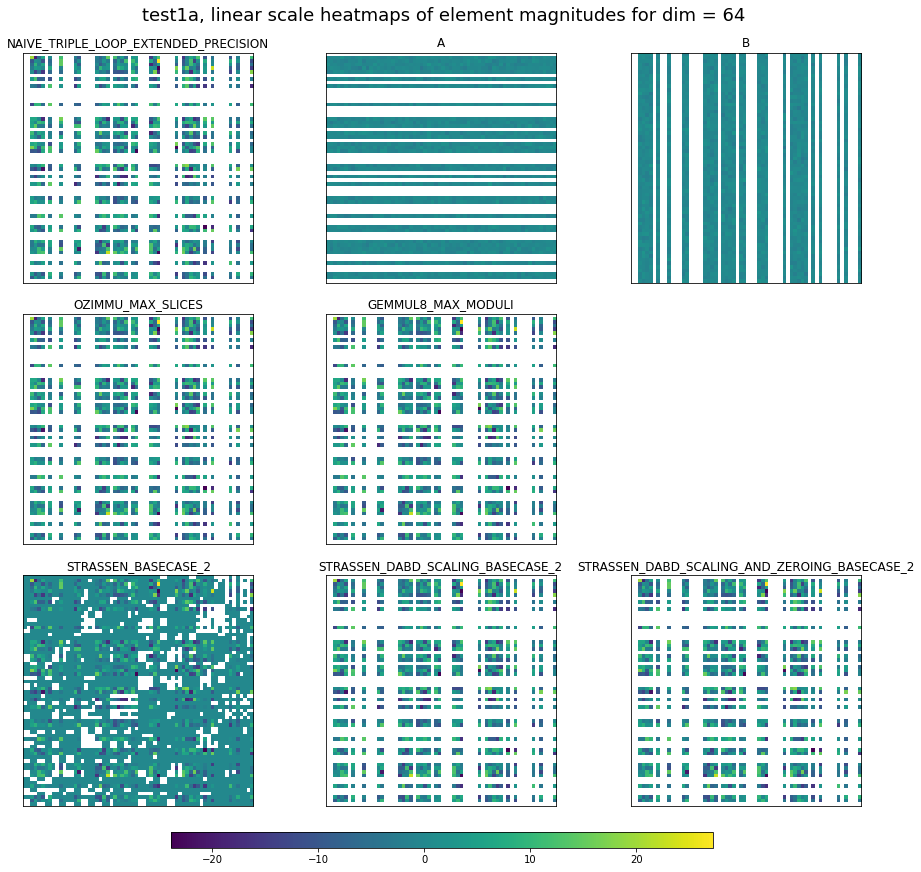

In [63]:
fig = magnitude_heatmaps(
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1a",
    problem_size = 64,
    n_rows = 3,
    n_cols = 3,
    logscale = False,
    shared_colorbar = True,
)

Input Type          : test1a
Problem Size        : 64


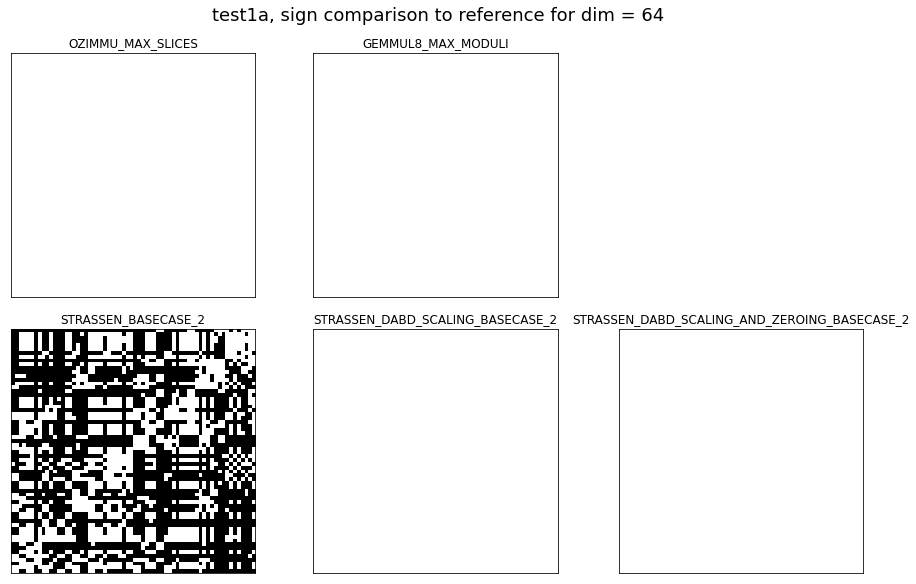

In [64]:
fig = sign_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    impls = [
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1a",
    problem_size = 64,
    n_rows = 2,
    n_cols = 3,
)

## Test 1-B
> Start with $A = randn(n,n)$ and $B = randn(n,n)$. Pick a random subset of $1<k<n$ rows of $A$, 
labeled $(i_1, \ldots, i_k)$, and $k$ random columns of $B$, labeled $(j_1, \ldots, j_k)$. For each $m\in [1:k]$, pick a 
random proper subset $S_m$ of $[1:n]$, and zero out entries $A(i_m,r)$ for all $r\in S_m$,
and zero out entries $B(s, j_m)$ for all $s$ not in $S_m$. This means that the dot
product $A(i_m, :)\cdot B(:, j_m) = (A\cdot B)(i_m, j_m)$ is exactly zero. If each $(A\cdot B)(i_m, j_m)$
is computed as a conventional dot product, it will be a sum of zeros and so exactly zero,
in any precision. But with any Strassen like algorithm, getting zero will require
exact cancellation, which is unlikely. And getting 
exactly $k$ zeros is even more unlikely.
Computing any nonzero value violates the requirement for an "A".
>
>Obviously other sparsity patterns for $A$ and $B$ might work too, but using “minimal”
sparsity as in Test\_1b would seem to maximize the chance of recognizing a Strassen-like
algorithm. \jwd{I verified this on some small numerical examples.} 
Since performant implementations of Strassen-like algorithms will not recurse down to 
$n=1$, but call an $O(n^3)$ algorithm instead on small enough matrices, 
Test\_1b can also be used
to “reverse engineer” the size $n_0$ of matrices at or below which an $O(n^3)$
algorithm is used, by finding the largest matrix that still passes Test\_1b. 
% We use this fact below?

>A failure to compute the expected $k$ zero entries is a clear signal that a
Strassen-like algorithm is being used. In other words, there are no false positive
signals for Strassen.
However, there is another way for a Strassen-like algorithm to ``game'' Test\_1b, 
by setting computed entries of $C$ less than an error bound to zero\footnotemark[1].
Since our test code will be public, a vendor could read our test code and 
precisely decide what this threshold would be. By first scaling the rows of $A$ and 
columns of $B$ to have unit norms (as described in the last paragraph of
Section~\ref{sec:grading}), and setting small values of 
$\hat{C} = (D_1 \cdot A) \cdot (B \cdot D_2)$ to zero this would make the behavior
hard to distinguish from an $O(n^3)$ algorithm using 
emulation, eg.
\cite{Uchino_Ozaki_Imamura_2024}, which earns a "B".

__As expected:__
- __Test 1-B defeats Strassen + DABD scaling alone__
- __Strassen + DABD scaling + zeroing successfully games Test 1-B__

Input Type          : test1b
Problem Size        : 64
Logscale?           : False
Shared Colorbar?    : True


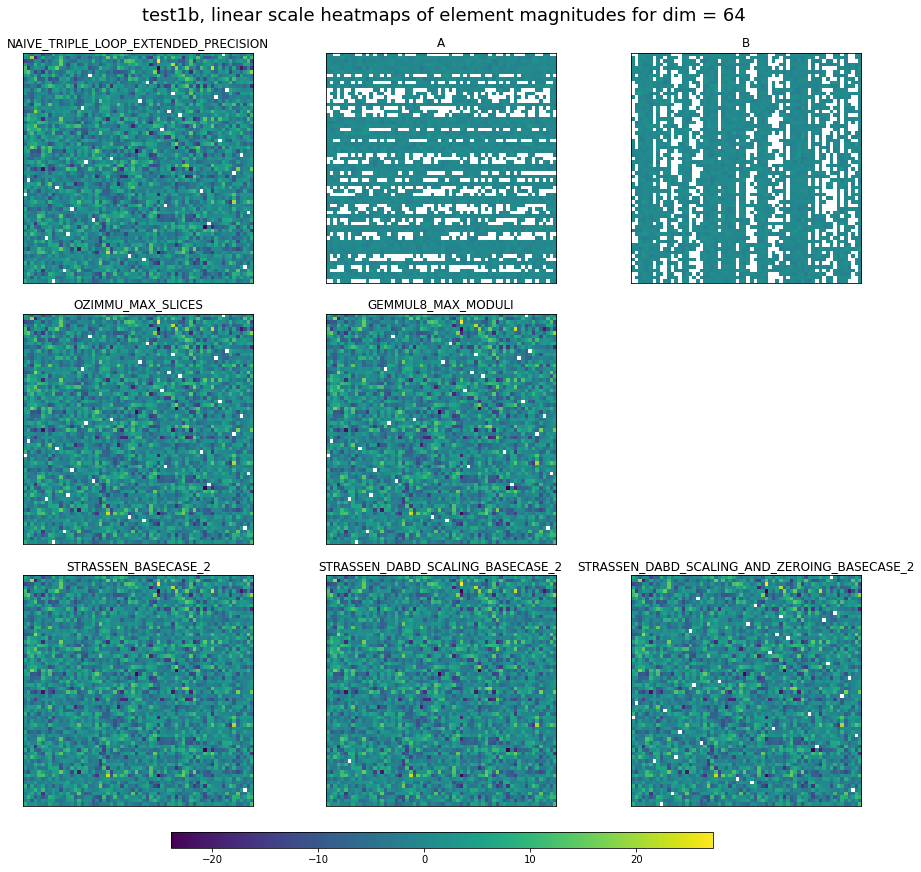

In [65]:
fig = magnitude_heatmaps(
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1b",
    problem_size = 64,
    n_rows = 3,
    n_cols = 3,
    logscale = False,
    shared_colorbar = True,
)

Input Type          : test1b
Problem Size        : 64


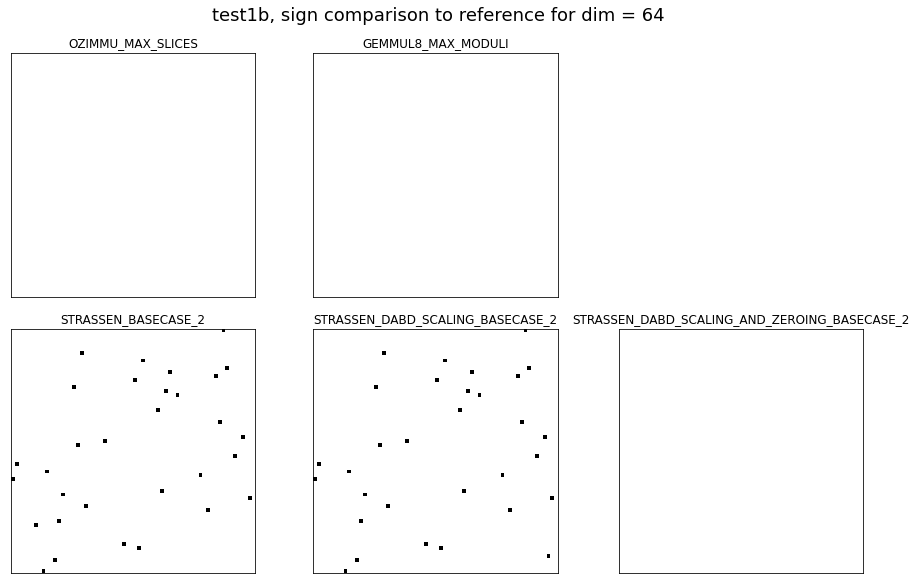

In [66]:
fig = sign_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    impls = [
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1b",
    problem_size = 64,
    n_rows = 2,
    n_cols = 3,
)

## Test 1-C
> We strengthen Test\_1b so that only an $O(n^3)$ algorithm using
conventional floating point can pass it. We take the test matrices $A$ and $B$
proposed for Test\_1b, and in some subset of the $k$ pairs of
rows $A(i_m,:)$ and columns $B(:,j_m)$, we choose a 
random $k_m$ and
% common zero entry $A(i_m,k_m)=B(k_m,j_m)=0$, and 
set $A(i_m,k_m)=B(k_m,j_m)=x$, so
that the correct value of $C(i_m,j_m)=x^2$. 
If we choose the nonzero entries in row $i_m$ of $A$
and column $j_m$ of $B$ that are multiplied by zeros
to be close to $\sqrt{OV}$, $x$ to be close to
$\sqrt{UN}$, and the other entries of $A$ and $B$
to be $O(1)$, then scaling $D_1 \cdot A$ 
(resp. $B \cdot D_2$) to have unit row (resp. column)
norms will make the $x^2$ values underflow to zero, causing an incorrect value $C(i_m,j_m)=0$.
Scaling by $D_3$ will not change the matrices (much)
since all the column norms of $A$ and row norms of $B$
are close to $\sqrt{OV}$.
A Strassen-like algorithm will not compute $x^2$
accurately w.h.p., whether or not it sets tiny entries
of $C$ to zero.
And the use of emulation will set the entries near
$\sqrt{UN}$ to zero, so that an $O(n^3)$ algorithm using
emulation will also compute 0 instead of $x^2$.
In other words, Test\_1c should reliably distinguish
an $O(n^3)$ algorithm using classic floating point,
which deserves an ''A'' grade, from the alternatives.

__As expected:__
- __Test 1-C defeats all non (O(n^3) + FP64) implementations__

Input Type          : test1c
Problem Size        : 64
Logscale?           : False
Shared Colorbar?    : True


/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/matplotlib/image.py:449: RuntimeWarning:

overflow encountered in double_scalars

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/matplotlib/image.py:454: RuntimeWarning:

overflow encountered in double_scalars



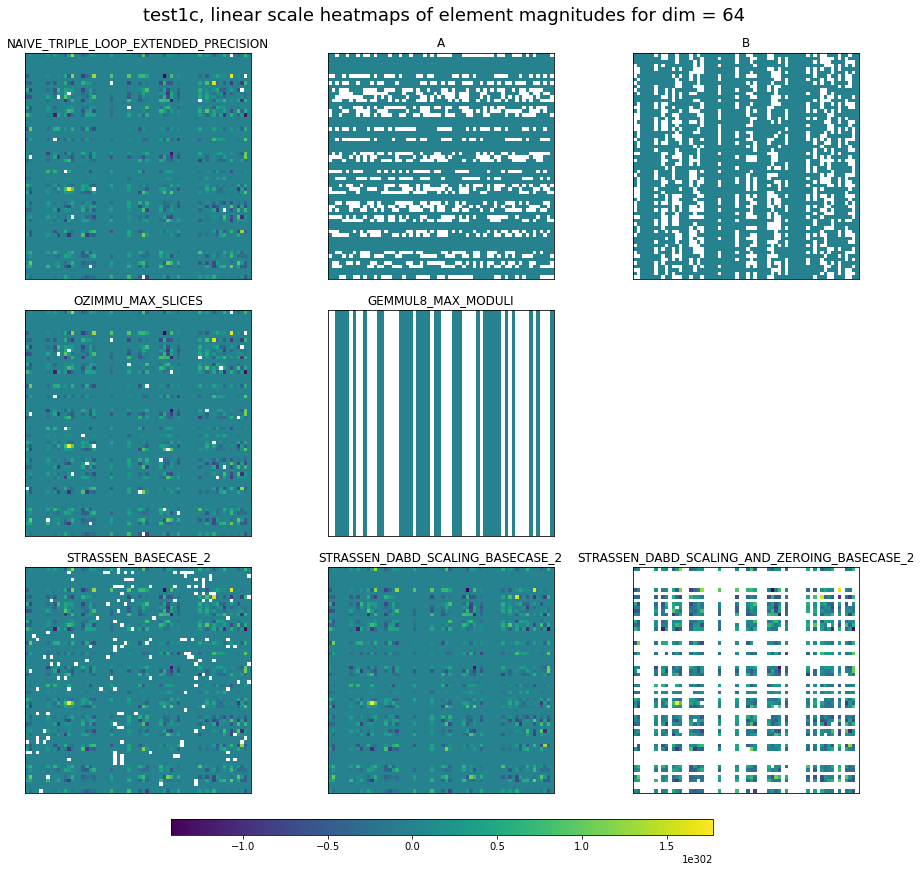

In [67]:
fig = magnitude_heatmaps(
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1c",
    problem_size = 64,
    n_rows = 3,
    n_cols = 3,
    logscale = False,
    shared_colorbar = True,
)

Input Type          : test1c
Problem Size        : 64


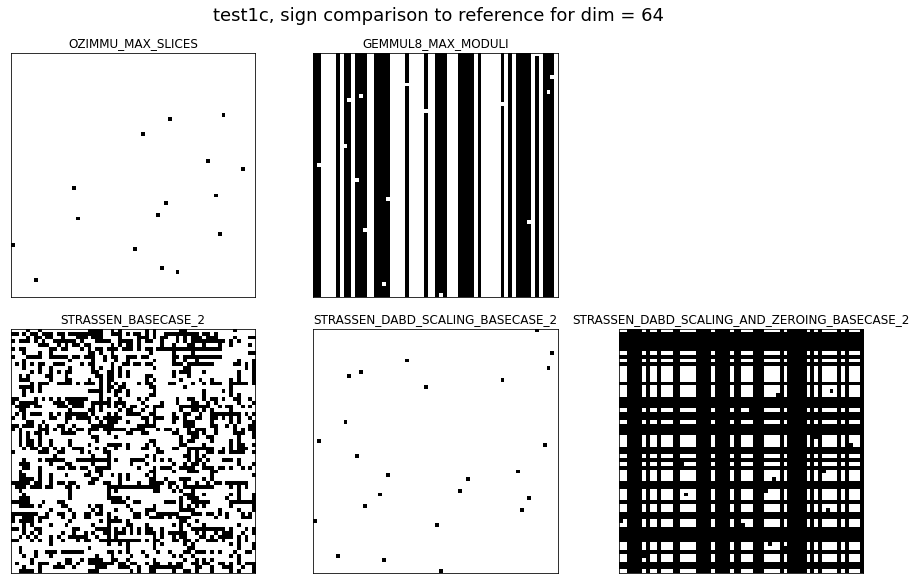

In [68]:
fig = sign_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    impls = [
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        '',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test1c",
    problem_size = 64,
    n_rows = 2,
    n_cols = 3,
)

# Test 2

## Test-2A
> Let $x = rand(1,n) + 1$ be a random vector with entries in the range [1,2].
Let $D$ be a diagonal matrix with entries equal to powers of two, ranging
from close to overflow to close to underflow, with roughly evenly spaced
exponents. Let $y = x\cdot D$ and $z^T = D^{-1}\cdot x^T$, so that $y\cdot z^T = x\cdot x^T = O(n)$ would be 
computed to high relative accuracy using standard floating point, but an $O(n^3)$ algorithm with emulation
would result in a high relative error unless the entire exponent
range is represented. Now let each row of A equal $y$ and each column of
B equal $z^T$, and test that each entry is accurate, by comparing to the
floating point result
> 
> Test\_2a is easily gamable, for $O(n^2)$ extra cost, by replacing
$A$ by $A\cdot D_3$ and $B$ by $D_3^{-1}\cdot B$, where the diagonal matrix $D_3$ is chosen
so that the i-th column of A and i-th row of B each has (about) the same norm,
effectively changing each row of $A\cdot D_3$ back to $x$ and each column of $D_3^{-1}\cdot B$ 
back to $x^T$. Note that this diagonal scaling  will
also greatly improve the accuracy 
of Strassen, by reducing $\|A\| \cdot \|B\| = O(OV^2)$ 
to $\|A\cdot D_3\|\cdot \|D_3^{-1}\cdot B\| = O(1)$.

__As expected:__
- __Both vanilla emulation and vanilla Strassen fail Test-2A.__
- __Adding ADDB scaling games Test-2A__

__(Note that `STRASSEN_BASECASE_2` is missing because of NaN values in C, likely from overflows somewhere in the recursion)__

Input Type          : test2a
Problem Size        : 64
Logscale?           : True
Shared Colorbar?    : True


/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:37: RuntimeWarning:

divide by zero encountered in log10

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:67: RuntimeWarning:

divide by zero encountered in log10



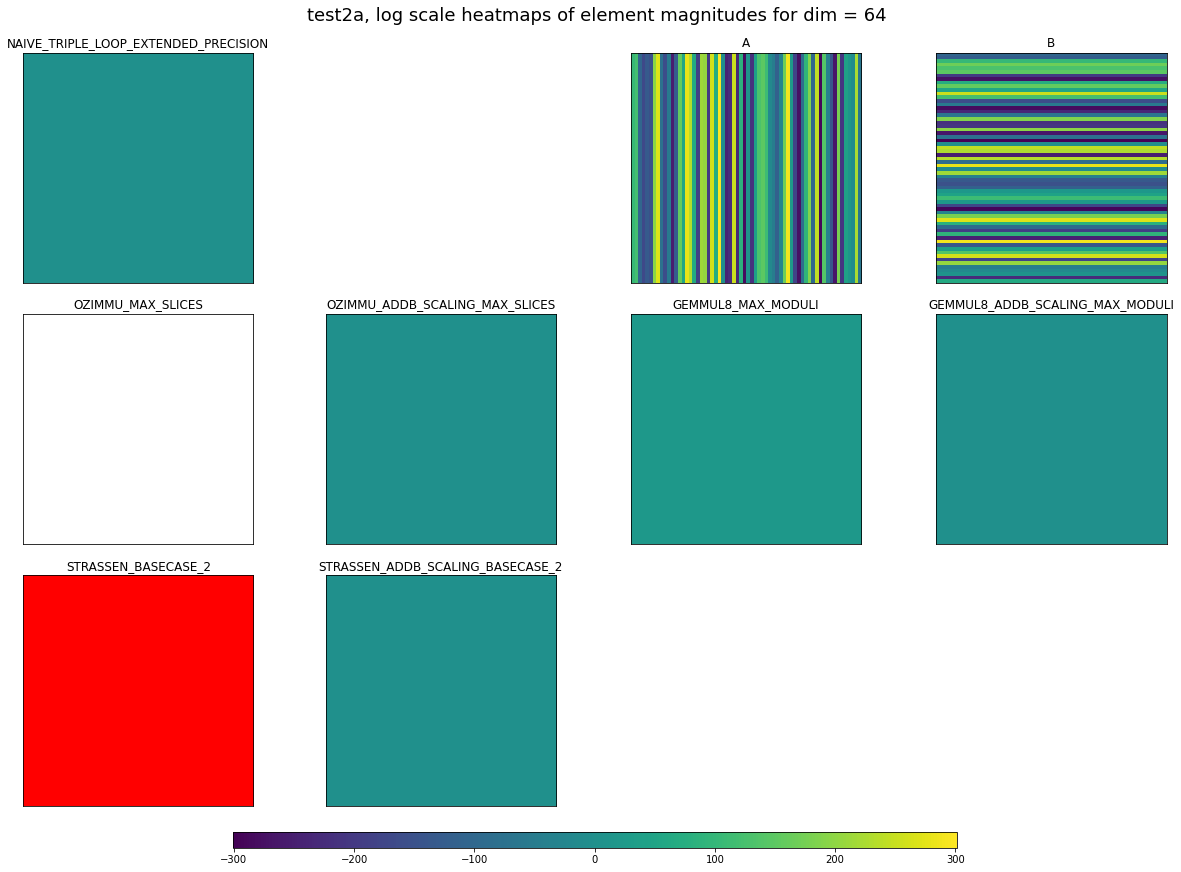

In [73]:
fig = magnitude_heatmaps(
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        '',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        '',
        '',
    ],
    input_type = "test2a",
    problem_size = 64,
    n_rows = 3,
    n_cols = 4,
    logscale = True,
    shared_colorbar = True,
)

Input Type          : test2a
Problem Size        : 64
Error Function      : error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
Logscale?           : True
Shared Colorbar?    : True
Reference Precision : fp80
Error Ceiling       : None


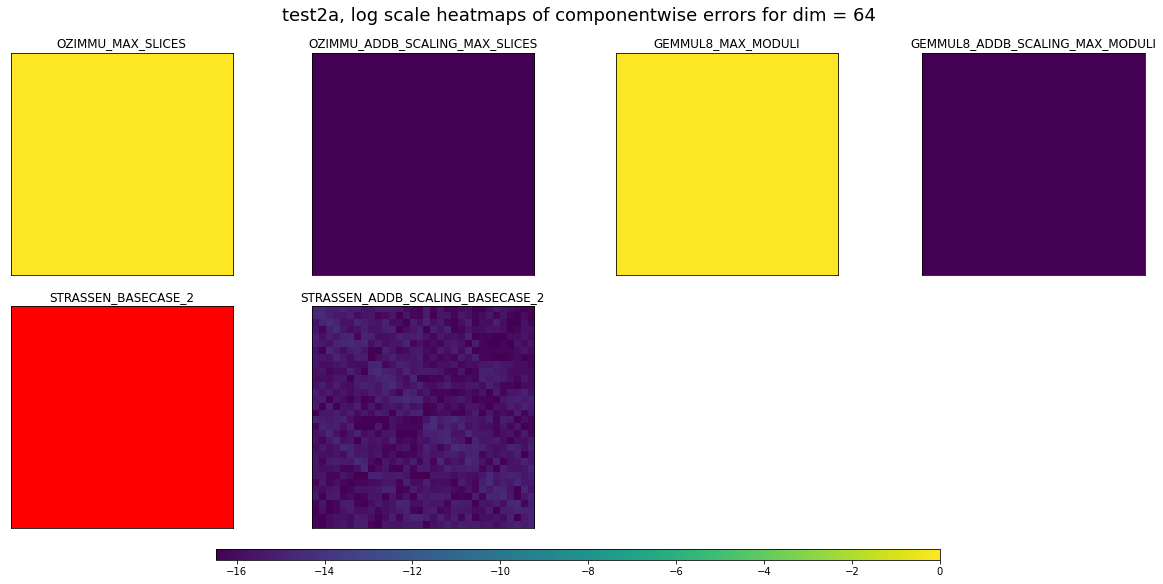

In [88]:
fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
    impls = [
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        '',
        '',
    ],
    input_type = "test2a",
    problem_size = 64,
    n_rows = 2,
    n_cols = 4, 
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
)

## Test-2B
> We can try to prevent the gaming of Test\_2a as follows: for each $i \in [1:n]$,
circularly shift each row of $A$ right by $i$, and circularly shift each column of $B$
down by $i$. Then each row and column of $A$ and of $B$ has the same norm, so any
diagonal scaling is pointless, and the diagonal entries of $A\cdot B$ should all equal
$x\cdot x^T$ to high relative accuracy in floating point. We should also reduce the range of 
numbers in the diagonal matrix $D$ used to compute $y=x\cdot D$ to go from roughly $\sqrt{UN}$ to
$\sqrt{OV}$, to avoid underflow and overflow.

Input Type          : test2c
Problem Size        : 64
Logscale?           : True
Shared Colorbar?    : True


/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:37: RuntimeWarning:

divide by zero encountered in log10

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:37: RuntimeWarning:

invalid value encountered in log10

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:67: RuntimeWarning:

divide by zero encountered in log10

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:67: RuntimeWarning:

invalid value encountered in log10



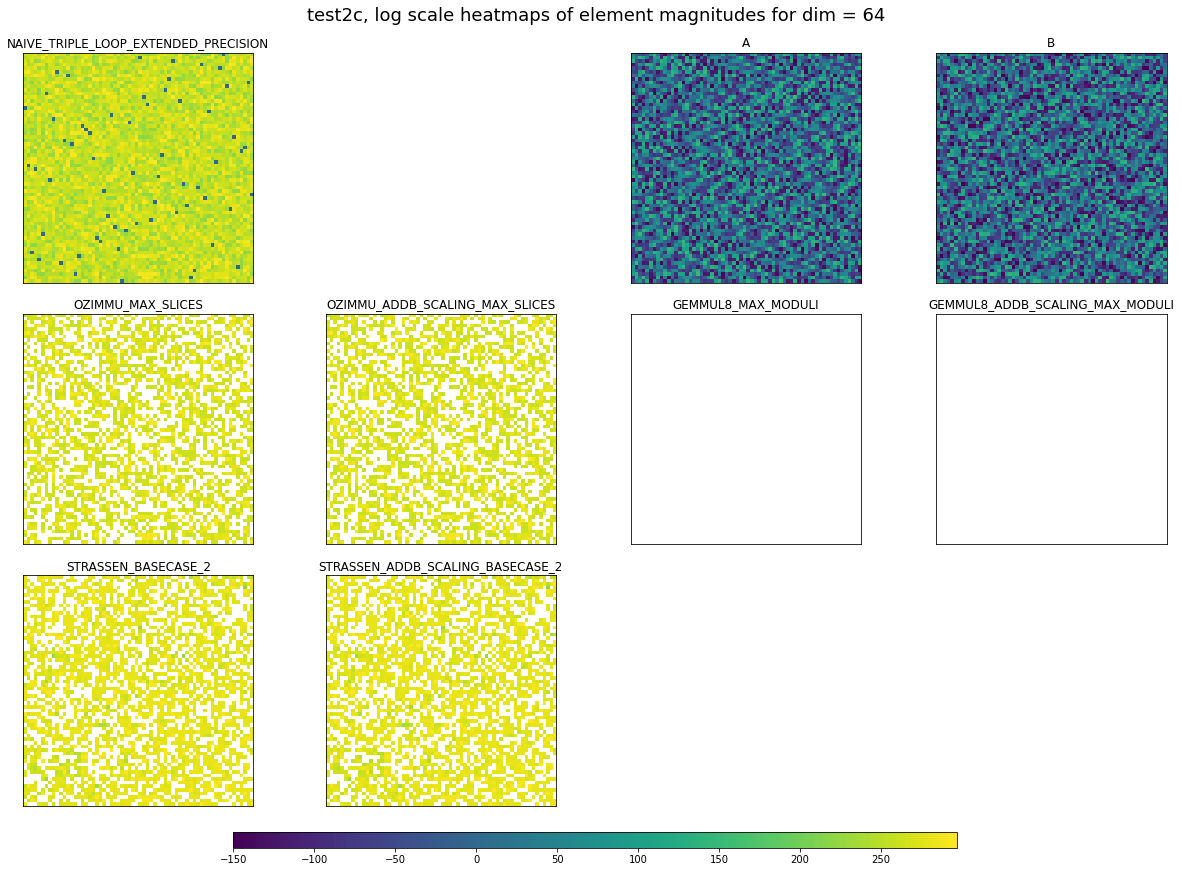

In [86]:
fig = magnitude_heatmaps(
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        '',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        '',
        '',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 3,fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
    impls = [
        'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
        '',
        'A',
        'B',
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        '',
        '',
    ],
    input_type = "test2a",
    problem_size = 64,
    n_rows = 3,
    n_cols = 4, 
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
)
    n_cols = 4,
    logscale = True,
    shared_colorbar = True,
)

Input Type          : test2c
Problem Size        : 64
Error Function      : error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
Logscale?           : True
Shared Colorbar?    : True
Reference Precision : fp80
Error Ceiling       : None


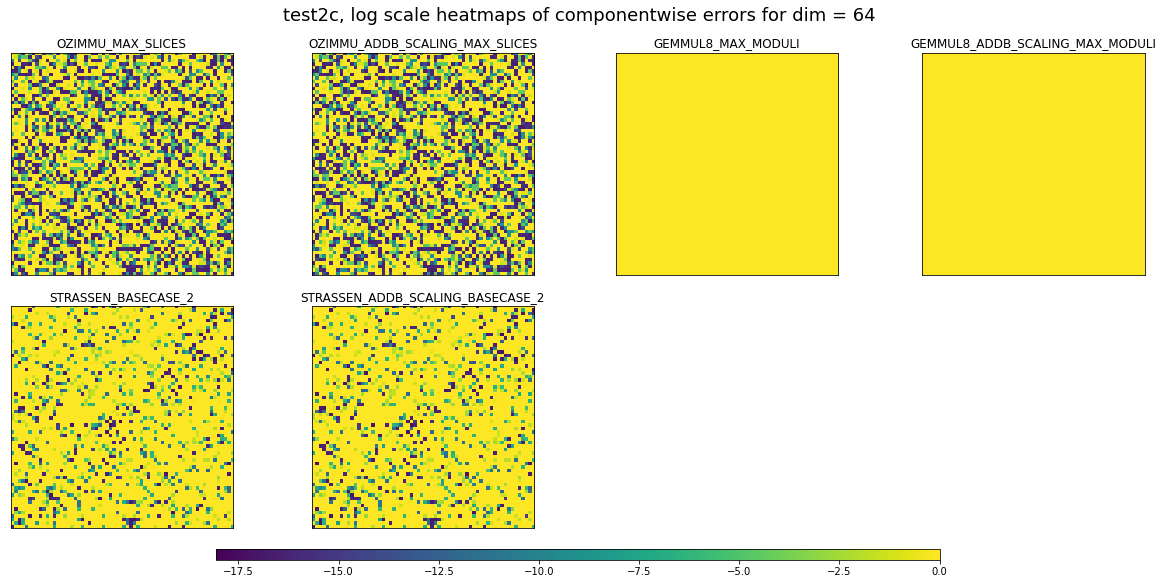

In [89]:
fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
    impls = [
        'OZIMMU_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'OZIMMU_ADDB_SCALING_MAX_SLICES-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'GEMMUL8_ADDB_SCALING_MAX_MODULI-2.0.10-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
        'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
        '',
        '',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 2,
    n_cols = 4, 
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
)

In [ ]:
"""
input_type = "test2b"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-2B, Max Componentwise f(n) factor vs Dim", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()
"""

/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:32: RuntimeWarning:

divide by zero encountered in log10



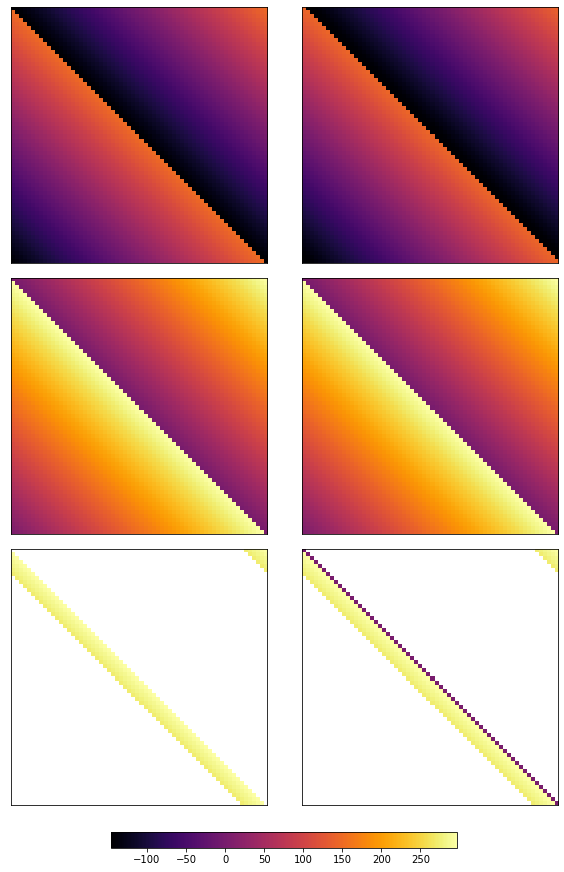

In [11]:
input_type = "test2b"
problem_size = 64

query={
    "input_type" : input_type,
    "m" : problem_size
}

query["matrix_name"] = "A"
A = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)

query["matrix_name"] = "B"
B = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)

query["matrix_name"] = "OZIMMU_ADDB_SCALING_AUTO_0"
C_ozimmu_addb_scaling = get_matrix(query, metadata_df, matrices_dict)

query["matrix_name"] = "OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0"
C_ozimmu_addb_scaling_and_fp64_diag = get_matrix(query, metadata_df, matrices_dict)

query["matrix_name"] = "NETLIB"
C_netlib = get_matrix(query, metadata_df, matrices_dict)

query["matrix_name"] = ref_impl
C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)

def get_exponent_part(x):
    _, y = np.frexp(x)
    return y

def plot(ax, data, cmap, norm):
    im = ax.imshow(np.log10(data).astype(np.float64), cmap=cmap, norm=norm)
    overlay = np.zeros((*data.shape, 4))  # fully transparent by default
    overlay[~np.isfinite(data)] = [1, 0, 0, 1]  # red for nonfinite
    overlay[data == 0]          = [1, 1, 1, 1]  # white for zero
    ax.imshow(overlay)
    return im
    
n_rows = 3
n_cols = 2

cmap = mpl.cm.get_cmap('inferno')
normalizer = mpl.colors.Normalize(vmin=np.min(np.log10(A)), vmax=np.max(np.log10(C_ref)))

# fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
# im = axs[0,0].imshow(get_exponent_part(A), cmap=cmap, norm=normalizer)
# im = axs[0,1].imshow(get_exponent_part(B), cmap=cmap, norm=normalizer)
# im = axs[1,0].imshow(get_exponent_part(C_ref), cmap=cmap, norm=normalizer)
# im = axs[1,1].imshow(get_exponent_part(C_netlib), cmap=cmap, norm=normalizer)
# im = axs[2,0].imshow(get_exponent_part(C_ozimmu_addb_scaling), cmap=cmap, norm=normalizer)
# im = axs[2,1].imshow(get_exponent_part(C_ozimmu_addb_scaling_and_fp64_diag), cmap=cmap, norm=normalizer)
# fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.6, location = "bottom")

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
im = plot(axs[0,0], A, cmap=cmap, norm=normalizer)
axs[0,0].axes.xaxis.set_ticks([])
axs[0,0].axes.yaxis.set_ticks([])
im = plot(axs[0,1], B, cmap=cmap, norm=normalizer)
axs[0,1].axes.xaxis.set_ticks([])
axs[0,1].axes.yaxis.set_ticks([])
im = plot(axs[1,0], C_ref, cmap=cmap, norm=normalizer)
axs[1,0].axes.xaxis.set_ticks([])
axs[1,0].axes.yaxis.set_ticks([])
im = plot(axs[1,1], C_netlib, cmap=cmap, norm=normalizer)
axs[1,1].axes.xaxis.set_ticks([])
axs[1,1].axes.yaxis.set_ticks([])
im = plot(axs[2,0], C_ozimmu_addb_scaling, cmap=cmap, norm=normalizer)
axs[2,0].axes.xaxis.set_ticks([])
axs[2,0].axes.yaxis.set_ticks([])
im = plot(axs[2,1], C_ozimmu_addb_scaling_and_fp64_diag, cmap=cmap, norm=normalizer)
axs[2,1].axes.xaxis.set_ticks([])
axs[2,1].axes.yaxis.set_ticks([])
fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.6, location = "bottom")

In [108]:
x = (0,0)
print(f"C_ref[{x}] = {C_ref[x]}")
print(f"C_netlib[{x}] = {C_netlib[x]}")
#print(f"C_ozimmu_addb_scaling[{x}] = {C_ozimmu_addb_scaling[x]}")
#print(f"C_ozimmu_addb_scaling_and_fp64_diag[{x}] = {C_ozimmu_addb_scaling_and_fp64_diag[x]}")
print(f"A exponents:\n{get_exponent_part(A[x[0], :])}")
print(f"B exponents:\n{get_exponent_part(B[:, x[1]])}")
print(f"A*B exponents:\n{get_exponent_part(A[x[0], :]*B[:, x[1]])}")
print(f"A*B:\n{A[x[0], :]*B[:, x[1]]}")
print(f"sum(A*B):{np.sum(A[x[0], :]*B[:, x[1]])}")

C_ref[(0, 0)] = 154.45792222334464
C_netlib[(0, 0)] = 154.4579222233446
A exponents:
[ 172  204 -170 -280 -217 -249  329  454 -124 -264  -92 -420 -202  266
   94  469  391  110 -311  360  344 -327  438  126  501    1 -405 -374
  422 -389  141 -467   16 -358   63  219  251  188  -30  -77 -186  -45
  282  485   47 -295 -452 -139  157  313 -155  407 -483  235  -61 -233
 -436  297 -342   79   32  -14  376 -108]
B exponents:
[-170 -202  172  282  219  251 -327 -452  126  266   94  422  204 -264
  -92 -467 -389 -108  313 -358 -342  329 -436 -124 -499    1  407  376
 -420  391 -139  469  -14  360  -61 -217 -249 -186   32   79  188   47
 -280 -483  -45  297  454  141 -155 -311  157 -405  485 -233   63  235
  438 -295  344  -77  -30   16 -374  110]
A*B exponents:
[2 2 2 2 2 1 1 1 1 2 2 2 1 2 1 2 1 2 1 2 2 2 2 2 2 2 2 2 1 2 1 2 1 1 1 1 1
 1 2 2 2 2 1 2 2 1 1 2 2 1 1 2 2 2 2 2 2 2 2 2 1 2 1 2]
A*B:
[2.53715397 3.40131614 3.45196193 3.41233898 2.63595908 1.91651271
 1.68359605 1.11664231 1.6196540

In [109]:
x = (0,1)
print(f"C_ref[{x}] = {C_ref[x]}")
print(f"C_netlib[{x}] = {C_netlib[x]}")
#print(f"C_ozimmu_addb_scaling[{x}] = {C_ozimmu_addb_scaling[x]}")
#print(f"C_ozimmu_addb_scaling_and_fp64_diag[{x}] = {C_ozimmu_addb_scaling_and_fp64_diag[x]}")
print(f"A exponents:\n{get_exponent_part(A[x[0], :])}")
print(f"B exponents:\n{get_exponent_part(B[:, x[1]])}")
print(f"A*B exponents:\n{get_exponent_part(A[x[0], :]*B[:, x[1]])}")
print(f"A*B:\n{A[x[0], :]*B[:, x[1]]}")
print(f"sum(A*B):{np.sum(A[x[0], :]*B[:, x[1]])}")

C_ref[(0, 1)] = 8.105248237221026e+239
C_netlib[(0, 1)] = 8.105248237221026e+239
A exponents:
[ 172  204 -170 -280 -217 -249  329  454 -124 -264  -92 -420 -202  266
   94  469  391  110 -311  360  344 -327  438  126  501    1 -405 -374
  422 -389  141 -467   16 -358   63  219  251  188  -30  -77 -186  -45
  282  485   47 -295 -452 -139  157  313 -155  407 -483  235  -61 -233
 -436  297 -342   79   32  -14  376 -108]
B exponents:
[ 110 -170 -202  172  282  219  251 -327 -452  126  266   94  422  204
 -264  -92 -467 -389 -108  313 -358 -342  329 -436 -124 -499    1  407
  376 -420  391 -139  469  -14  360  -61 -217 -249 -186   32   79  188
   47 -280 -483  -45  297  454  141 -155 -311  157 -405  485 -233   63
  235  438 -295  344  -77  -30   16 -374]
A*B exponents:
[ 282   34 -372 -108   65  -30  579  126 -577 -139  174 -326  220  470
 -170  377  -76 -279 -419  673  -14 -669  767 -310  377 -498 -404   33
  797 -810  531 -606  485 -373  422  157   33  -62 -216  -45 -107  143
  329  205 -4

In [79]:
x = (0,2)
print(f"C_ref[{x}] = {C_ref[x]}")
print(f"C_netlib[{x}] = {C_netlib[x]}")
#print(f"C_ozimmu_addb_scaling[{x}] = {C_ozimmu_addb_scaling[x]}")
#print(f"C_ozimmu_addb_scaling_and_fp64_diag[{x}] = {C_ozimmu_addb_scaling_and_fp64_diag[x]}")
print(f"A exponents:\n{get_exponent_part(A[x[0], :])}")
print(f"B exponents:\n{get_exponent_part(B[:, x[1]])}")
print(f"A*B exponents:\n{get_exponent_part(A[x[0], :]*B[:, x[1]])}")
print(f"A*B:\n{A[x[0], :]*B[:, x[1]]}")
print(f"sum(A*B):{np.sum(A[x[0], :]*B[:, x[1]])}")

C_ref[(0, 2)] = 1.5216142728480582e+249
C_netlib[(0, 2)] = 1.5216142728480582e+249
A exponents:
[ 172  204 -170 -280 -217 -249  329  454 -124 -264  -92 -420 -202  266
   94  469  391  110 -311  360  344 -327  438  126  501    1 -405 -374
  422 -389  141 -467   16 -358   63  219  251  188  -30  -77 -186  -45
  282  485   47 -295 -452 -139  157  313 -155  407 -483  235  -61 -233
 -436  297 -342   79   32  -14  376 -108]
B exponents:
[-374  110 -170 -202  172  282  219  251 -327 -452  126  266   94  422
  204 -264  -92 -467 -389 -108  313 -358 -342  329 -436 -124 -499    1
  407  376 -420  391 -139  469  -14  360  -61 -217 -249 -186   32   79
  188   47 -280 -483  -45  297  454  141 -155 -311  157 -405  485 -233
   63  235  438 -295  344  -77  -30   16]
A*B exponents:
[-202  314 -340 -482  -45   33  548  704 -452 -717   34 -154 -108  688
  297  205  298 -357 -701  252  656 -685   96  455   65 -123 -904 -373
  828  -13 -280  -76 -124  110   48  578  189  -30 -279 -263 -154   34
  469  532 

In [11]:
x = (9,0)
print(f"C_ref[{x}] = {C_ref[x]}")
print(f"C_netlib[{x}] = {C_netlib[x]}")
print(f"C_ozimmu_addb_scaling[{x}] = {C_ozimmu_addb_scaling[x]}")
print(f"C_ozimmu_addb_scaling_and_fp64_diag[{x}] = {C_ozimmu_addb_scaling_and_fp64_diag[x]}")
print(f"A exponents:\n{get_exponent_part(A[x[0], :])}")
print(f"B exponents:\n{get_exponent_part(B[:, x[1]])}")
print(f"A*B exponents:\n{get_exponent_part(A[x[0], :]*B[:, x[1]])}")
exponent_distances = np.abs(get_exponent_part(A[x[0], :]) - get_exponent_part(B[:, x[1]]))
print(f"Distance between A and B exponents:\n{exponent_distances}")
print(f"max distance: {max(exponent_distances)}")

C_ref[(9, 0)] = 154.45792222334464
C_netlib[(9, 0)] = 154.4579222233446
C_ozimmu_addb_scaling[(9, 0)] = 154.45792222334464
C_ozimmu_addb_scaling_and_fp64_diag[(9, 0)] = 154.45792222334464
A exponents:
[ 344  407 -342 -561 -436 -499  657  907 -249 -530 -186 -842 -405  532
  188  938  782  219 -624  719  688 -655  876  251 1001    1 -811 -749
  844 -780  282 -936   32 -717  126  438  501  376  -61 -155 -374  -92
  563  969   94 -592 -905 -280  313  626 -311  813 -967  469 -124 -467
 -874  594 -686  157   63  -30  751 -217]
B exponents:
[-342 -405  344  563  438  501 -655 -905  251  532  188  844  407 -530
 -186 -936 -780 -217  626 -717 -686  657 -874 -249 -999    1  813  751
 -842  782 -280  938  -30  719 -124 -436 -499 -374   63  157  376   94
 -561 -967  -92  594  907  282 -311 -624  313 -811  969 -467  126  469
  876 -592  688 -155  -61   32 -749  219]
A*B exponents:
[2 2 2 2 2 1 1 1 1 2 2 2 1 2 1 2 1 2 1 2 2 2 2 2 2 2 2 2 1 2 1 2 1 1 1 1 1
 1 2 2 2 2 1 2 2 1 1 2 2 1 1 2 2 2 2 2 2 2 2

In [458]:
x = (10,0)
print(f"C_ref[{x}] = {C_ref[x]}")
print(f"C_netlib[{x}] = {C_netlib[x]}")
print(f"C_ozimmu_addb_scaling[{x}] = {C_ozimmu_addb_scaling[x]}")
print(f"C_ozimmu_addb_scaling_and_fp64_diag[{x}] = {C_ozimmu_addb_scaling_and_fp64_diag[x]}")
print(f"A exponents:\n{get_exponent_part(A[x[0], :])}")
print(f"B exponents:\n{get_exponent_part(B[:, x[1]])}")
print(f"A*B exponents:\n{get_exponent_part(A[x[0], :]*B[:, x[1]])}")
exponent_distances = np.abs(get_exponent_part(A[x[0], :]) - get_exponent_part(B[:, x[1]]))
print(f"Distance between A and B exponents:\n{exponent_distances}")
print(f"max distance: {max(exponent_distances)}")

C_ref[(10, 0)] = 1.3543221536010244e+255
C_netlib[(10, 0)] = 1.3543221536010244e+255
C_ozimmu_addb_scaling[(10, 0)] = 0.0
C_ozimmu_addb_scaling_and_fp64_diag[(10, 0)] = 0.0
A exponents:
[ 360  376  391  407  422  438  454  469  485  501 -483 -467 -452 -436
 -420 -405 -389 -374 -358 -342 -327 -311 -295 -280 -264 -249 -233 -217
 -202 -186 -170 -155 -139 -124 -108  -92  -77  -61  -45  -30  -14    1
   16   32   47   63   79   94  110  126  141  157  172  188  204  219
  235  251  266  282  297  313  329  344]
B exponents:
[ 485  469  454  438  422  407  391  376  360  344  329  313  297  282
  266  251  235  219  204  188  172  157  141  126  110   94   79   63
   47   32   16    1  -14  -30  -45  -61  -77  -92 -108 -124 -139 -155
 -170 -186 -202 -217 -233 -249 -264 -280 -295 -311 -327 -342 -358 -374
 -389 -405 -420 -436 -452 -467 -483 -499]
A*B exponents:
[ 845  845  845  845  844  845  844  844  844  845 -154 -154 -155 -154
 -154 -154 -155 -155 -155 -154 -155 -154 -154 -154 -154 -155 -1

## Test 2-C
> Unfortunately, Test\_2b is still gamable,
by using conventional floating point to compute just
the diagonal entries of $A \cdot B$ to high accuracy,
for an extra $O(n^2)$ cost. Instead, we can randomize the
locations of these $n$ accurate entries, so that it is
too expensive to detect their locations and compute them
with extra precision. Simply choose random permutation
matrices $P_1$ and $P_2$, and replace $A$ by $P_1 \cdot A$,
and $B$ by $B \cdot P_2$. The entries of the product
to test for accuracy are the nonzero entries of $P_1 \cdot P_2$.

In [16]:
fig = magnitude_heatmaps(
    impls = [
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       '',
       'A',
       'B',
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 4,
    n_cols = 4,
    logscale = True,
    shared_colorbar = True
)

Input Type          : test2c
Problem Size        : 64
Logscale?           : True
Shared Colorbar?    : True
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!
Found no matches!


/global/u2/j/jvanover/grading-the-blas/.venv/lib64/python3.6/site-packages/ipykernel_launcher.py:31: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray



TypeError: '<=' not supported between instances of 'NoneType' and 'float'

Input Type          : test2c
Problem Size        : 64
Error Function      : error_function = lambda C, C_ref : np.abs(C - C_ref) / np.abs(C_ref),
Logscale?           : True
Shared Colorbar?    : True
Reference Precision : fp80
Error Ceiling       : 1e+16


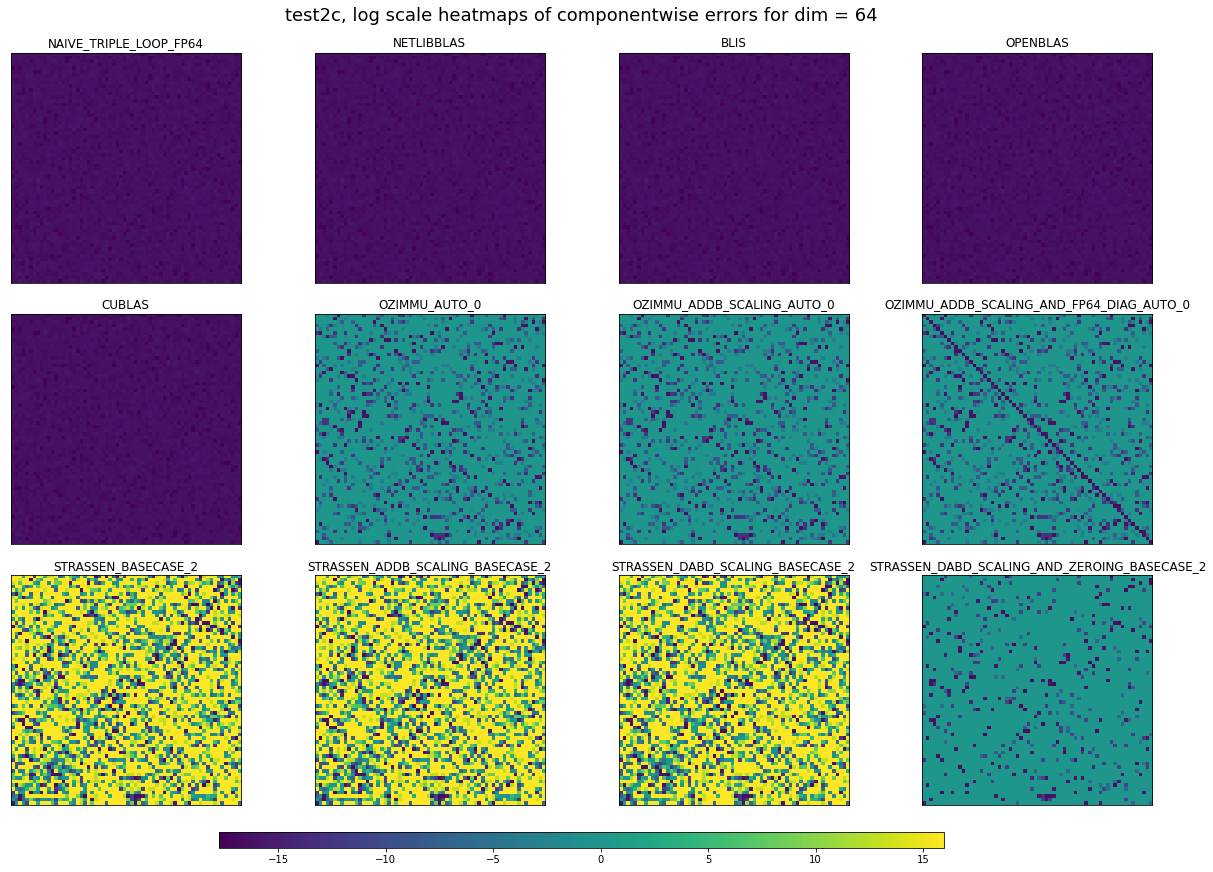

In [177]:
fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / np.abs(C_ref),
    impls = [
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 3,
    n_cols = 4, 
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = 1e16,
)

Input Type          : test2c
Problem Size        : 64
Error Function      : error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
Logscale?           : True
Shared Colorbar?    : True
Reference Precision : fp80
Error Ceiling       : None


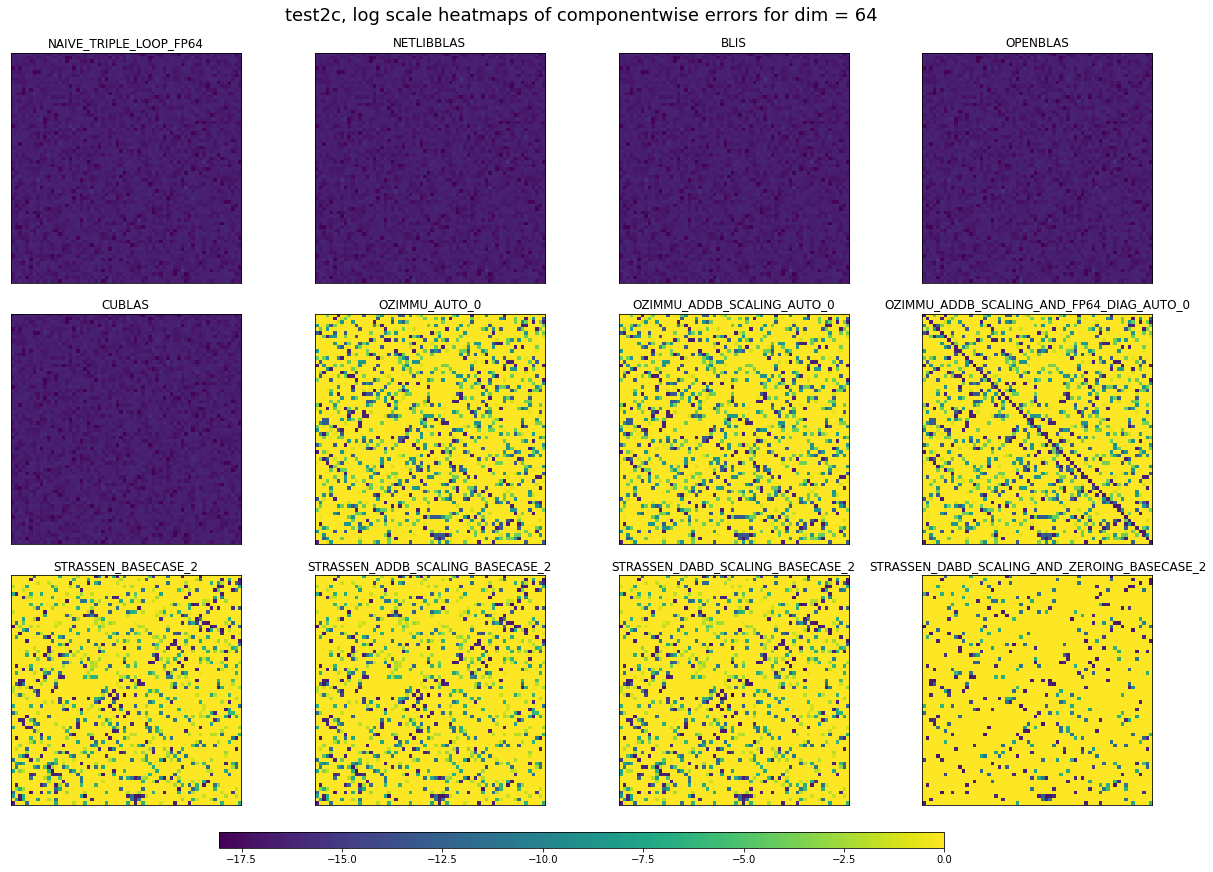

In [178]:
fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
    impls = [
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 3,
    n_cols = 4, 
    logscale = True,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
)

Input Type          : test2c
Problem Size        : 64
Error Function      : error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
Logscale?           : False
Shared Colorbar?    : True
Reference Precision : fp80
Error Ceiling       : None


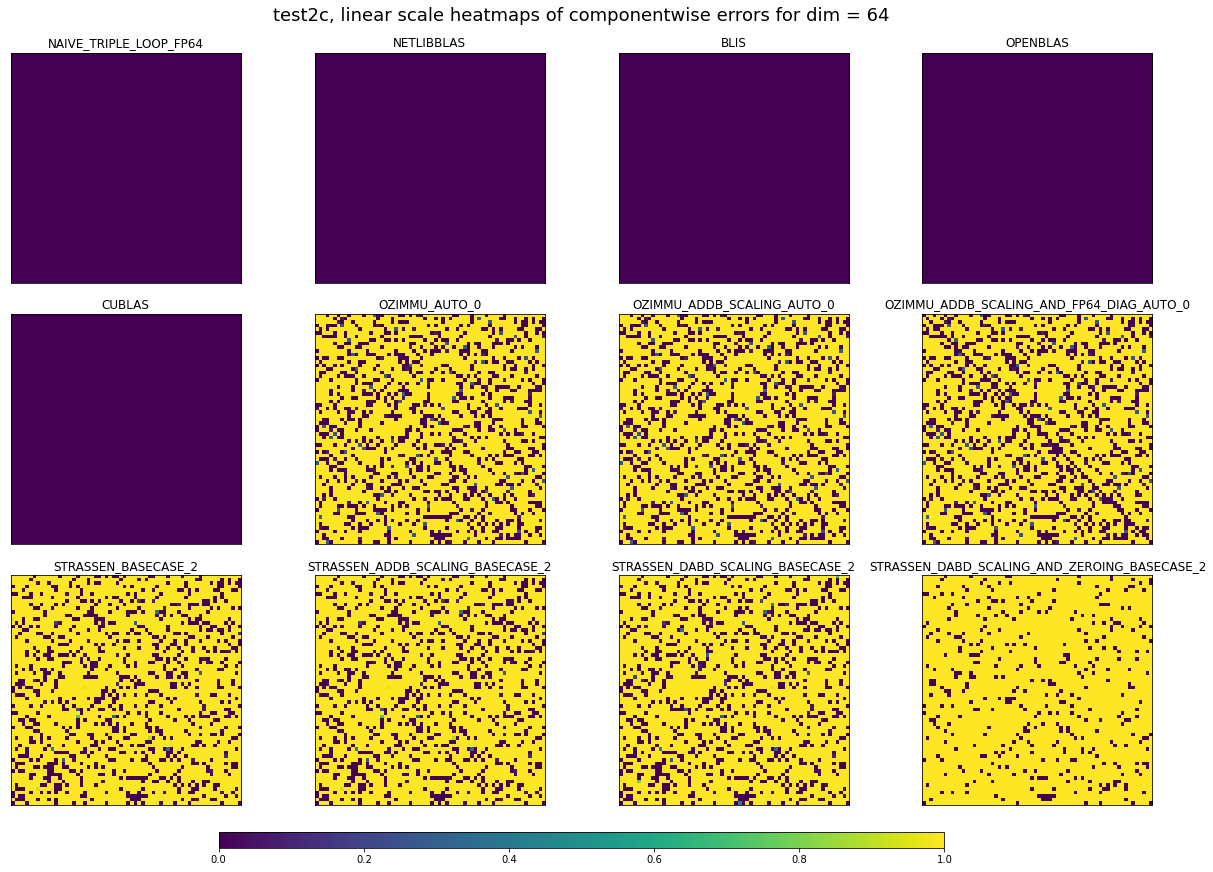

In [179]:
fig = error_heatmaps(
    ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    error_function = lambda C, C_ref : np.abs(C - C_ref) / (np.abs(C) + np.abs(C_ref)),
    impls = [
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
    ],
    input_type = "test2c",
    problem_size = 64,
    n_rows = 3,
    n_cols = 4, 
    logscale = False,
    shared_colorbar = True,
    extended_precision_reference = True,
    err_ceiling = None,
)

# Test 3

Input Type          : test3
Problem Size        : 64
Logscale?           : False
Shared Colorbar?    : False
Reference Precision : fp80
Error Ceiling       : 1e+16


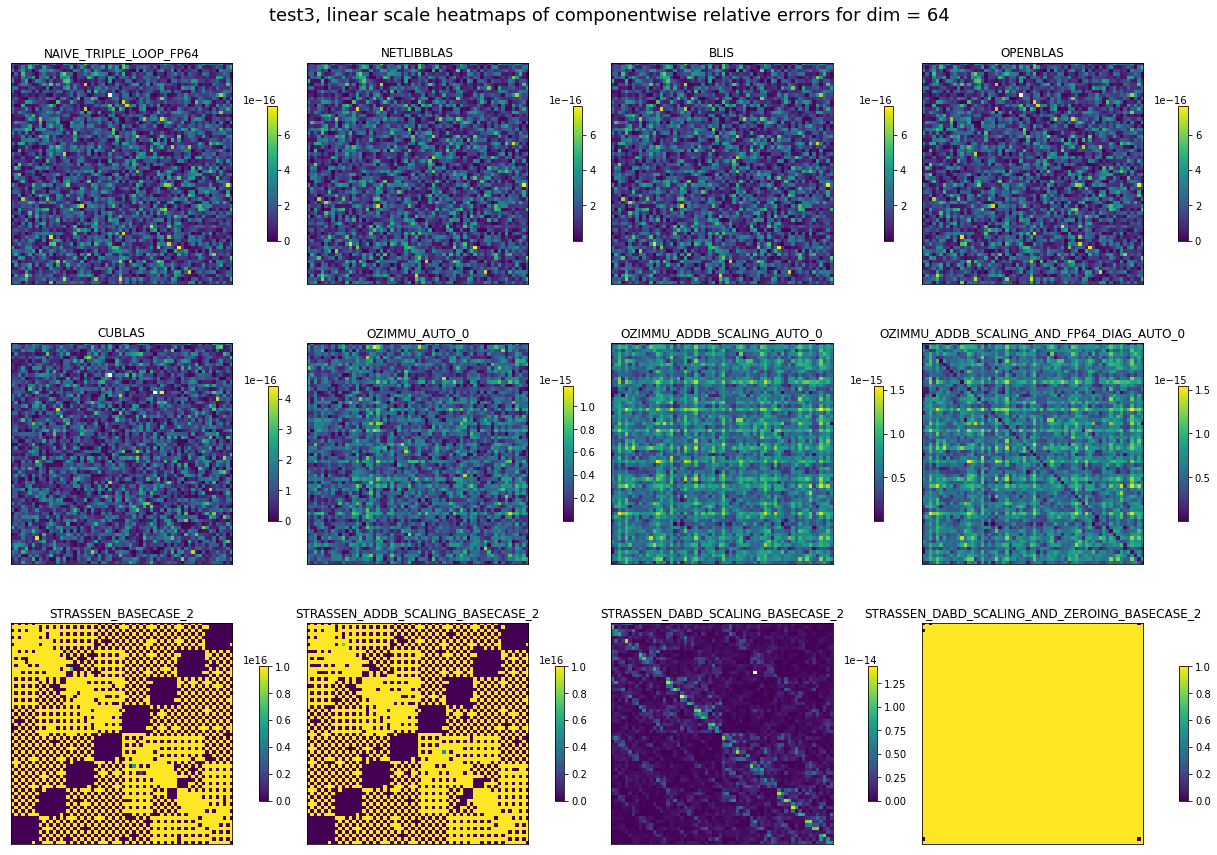

In [32]:
fig = relative_error_heatmaps(
    impls = impls,
    ref_impl = ref_impl,
    input_type = "test3",
    problem_size = problem_size,
    n_rows = n_rows,
    n_cols = n_cols,
    logscale = False,
    shared_colorbar = False,
    extended_precision_reference = True,
    err_ceiling = 1e16,
)

In [ ]:
query = {
    "matrix_name" : ref_impl,
    "input_type" : "U(1,2)",
    "m" : 32,
}

C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
C_ref - A

In [ ]:
impls = [
       #'A',
       #'B',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       #'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       #'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       #'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       #'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_ADDB_SCALING_AND_FP64_DIAG_AUTO_0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_ADDB_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_DABD_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       #'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'
]
n_rows=2
n_cols=4

In [ ]:
input_type = "test3"
problem_size = 64

data = []
for impl in impls:
    
    query = {
        "matrix_name" : impl,
        "m" : problem_size,
        "input_type" : input_type
    }
    
    C = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
    query["matrix_name"] = ref_impl
    C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
    data.append(np.abs(C - C_ref) / np.abs(C_ref))       
    data[-1] = np.clip(data[-1], a_min=None, a_max=10**16)

cmap = mpl.cm.get_cmap('viridis')
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4.2, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test 3, linear scale heatmaps of componentwise relative errors for dim = {problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="(Maximum relative error clipped to 10^16)", size=14, horizontalalignment="center")
for i, impl in enumerate(impls):
    if impl == ref_impl or "ZEROING" in impl:
        fig.delaxes(axs[i//n_cols, i%n_cols])
    else:
        print(impl)
        ax = axs[i//n_cols, i%n_cols]
        vmin = np.min(data[i])
        vmax = np.max(data[i])
        print(f"\tmin -> {vmin}")
        print(f"\tmax -> {vmax}")
        normalizer = mpl.colors.Normalize(0, vmax)
        im = ax.imshow(data[i], cmap=cmap, norm=normalizer)
        ax.figure.colorbar(im, ax=ax, shrink=0.5)
        ax.set_title(f"{impl.split('-')[0]}")
        ax.axes.xaxis.set_ticks([])
        ax.axes.yaxis.set_ticks([])
fig.show()

In [ ]:
input_type = "test3"
problem_size = 64

data = []
for impl in impls:

    if "NETLIBBLAS" not in impl:
        continue
        
    query = {
        "matrix_name" : impl,
        "m" : problem_size,
        "input_type" : input_type
    }
    
    C = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True).astype(np.float64)
    
    query["matrix_name"] = ref_impl
    C_ref = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
    query["matrix_name"] = "A"
    A = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)
    
    query["matrix_name"] = "B"
    B = get_matrix(query, metadata_df, matrices_dict, exact_str_match=True)

In [ ]:
rel_err = np.abs(np.abs(C - C_ref)/np.abs(C_ref))

In [ ]:
np.where(rel_err == np.min(rel_err))

In [ ]:
np.sum(A[31,:] * B[:,49])

In [ ]:
C[31,49]

In [ ]:
C_ref[31,49]

In [ ]:
C_ref[14,41] == C[14,41]

In [ ]:
np.abs(C_ref[31,49] - C[31,49])/np.abs(C_ref[31,49])